# Biography databases

Scholarly biographical dictionaries Cultura can be compared with: one biography downloaded from each (`building_scripts/dictionary_texts.py`).

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "5-annotations" / "building_scripts"))
from dictionary_texts import DB, DICTIONARIES, OUT

sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

texts = json.loads(OUT.read_text(encoding="utf-8"))
downloaded = {key: row for key, row in texts.items() if "text" in row and "pid" in DICTIONARIES[key]}
treccani = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "treccani_validation" / "treccani_texts.parquet")
labels = pl.DataFrame(duckdb.connect(str(DB), read_only=True).execute(
    "SELECT entity.qid AS wikidata_id, entity.label_en AS label FROM individual WHERE entity.qid IN (SELECT unnest(?)) AND entity.label_en IS NOT NULL",
    [treccani["wikidata_id"].to_list()]).fetchall(), schema=["wikidata_id", "label"], orient="row")
treccani_example = treccani.join(labels, on="wikidata_id").sort("wikidata_id").sample(1, seed=42).row(0, named=True)
print(f"Treccani example: {treccani_example['label']} ({treccani_example['wikidata_id']}), {treccani_example['dbi_url']}")
print(f"{len(DICTIONARIES)} dictionaries, {len(downloaded)} with a downloaded biography and a Wikidata identifier")

Treccani example: Anselm, Duke of Friuli (Q569615), https://www.treccani.it/enciclopedia/anselmo-di-nonantola-santo_(Dizionario-Biografico)/
21 dictionaries, 12 with a downloaded biography and a Wikidata identifier


## Overview table

In [2]:
REGIONS = {
    "treccani": "Italy",
    "deutsche_biographie": "German-speaking world", "oebl": "Austria-Hungary", "dwb": "Wales", "sbl": "Sweden",
    "nbl": "Norway", "dbl": "Denmark", "dcb": "Canada", "iranica": "Persia, Islamic East", "encykorea": "Korea",
    "sep": "Global / Philosophers", "mactutor": "Global / Mathematicians", "catholic_encyclopedia": "Global / Catholic Church",
}

overview = pl.DataFrame([
    {
        "Dictionary": DICTIONARIES[key]["name"],
        "Region / Topic": REGIONS[key],
        "Biography Example": row["label"],
        "Number of Characters": len(row["text"]),
    }
    for key, row in downloaded.items()
] + [{
    "Dictionary": "Dizionario Biografico degli Italiani (Treccani)",
    "Region / Topic": REGIONS["treccani"],
    "Biography Example": treccani_example["label"],
    "Number of Characters": len(treccani_example["text"]),
}]).sort("Dictionary")
assert overview["Dictionary"].is_unique().all() and overview["Biography Example"].null_count() == 0
overview.shape

(13, 4)

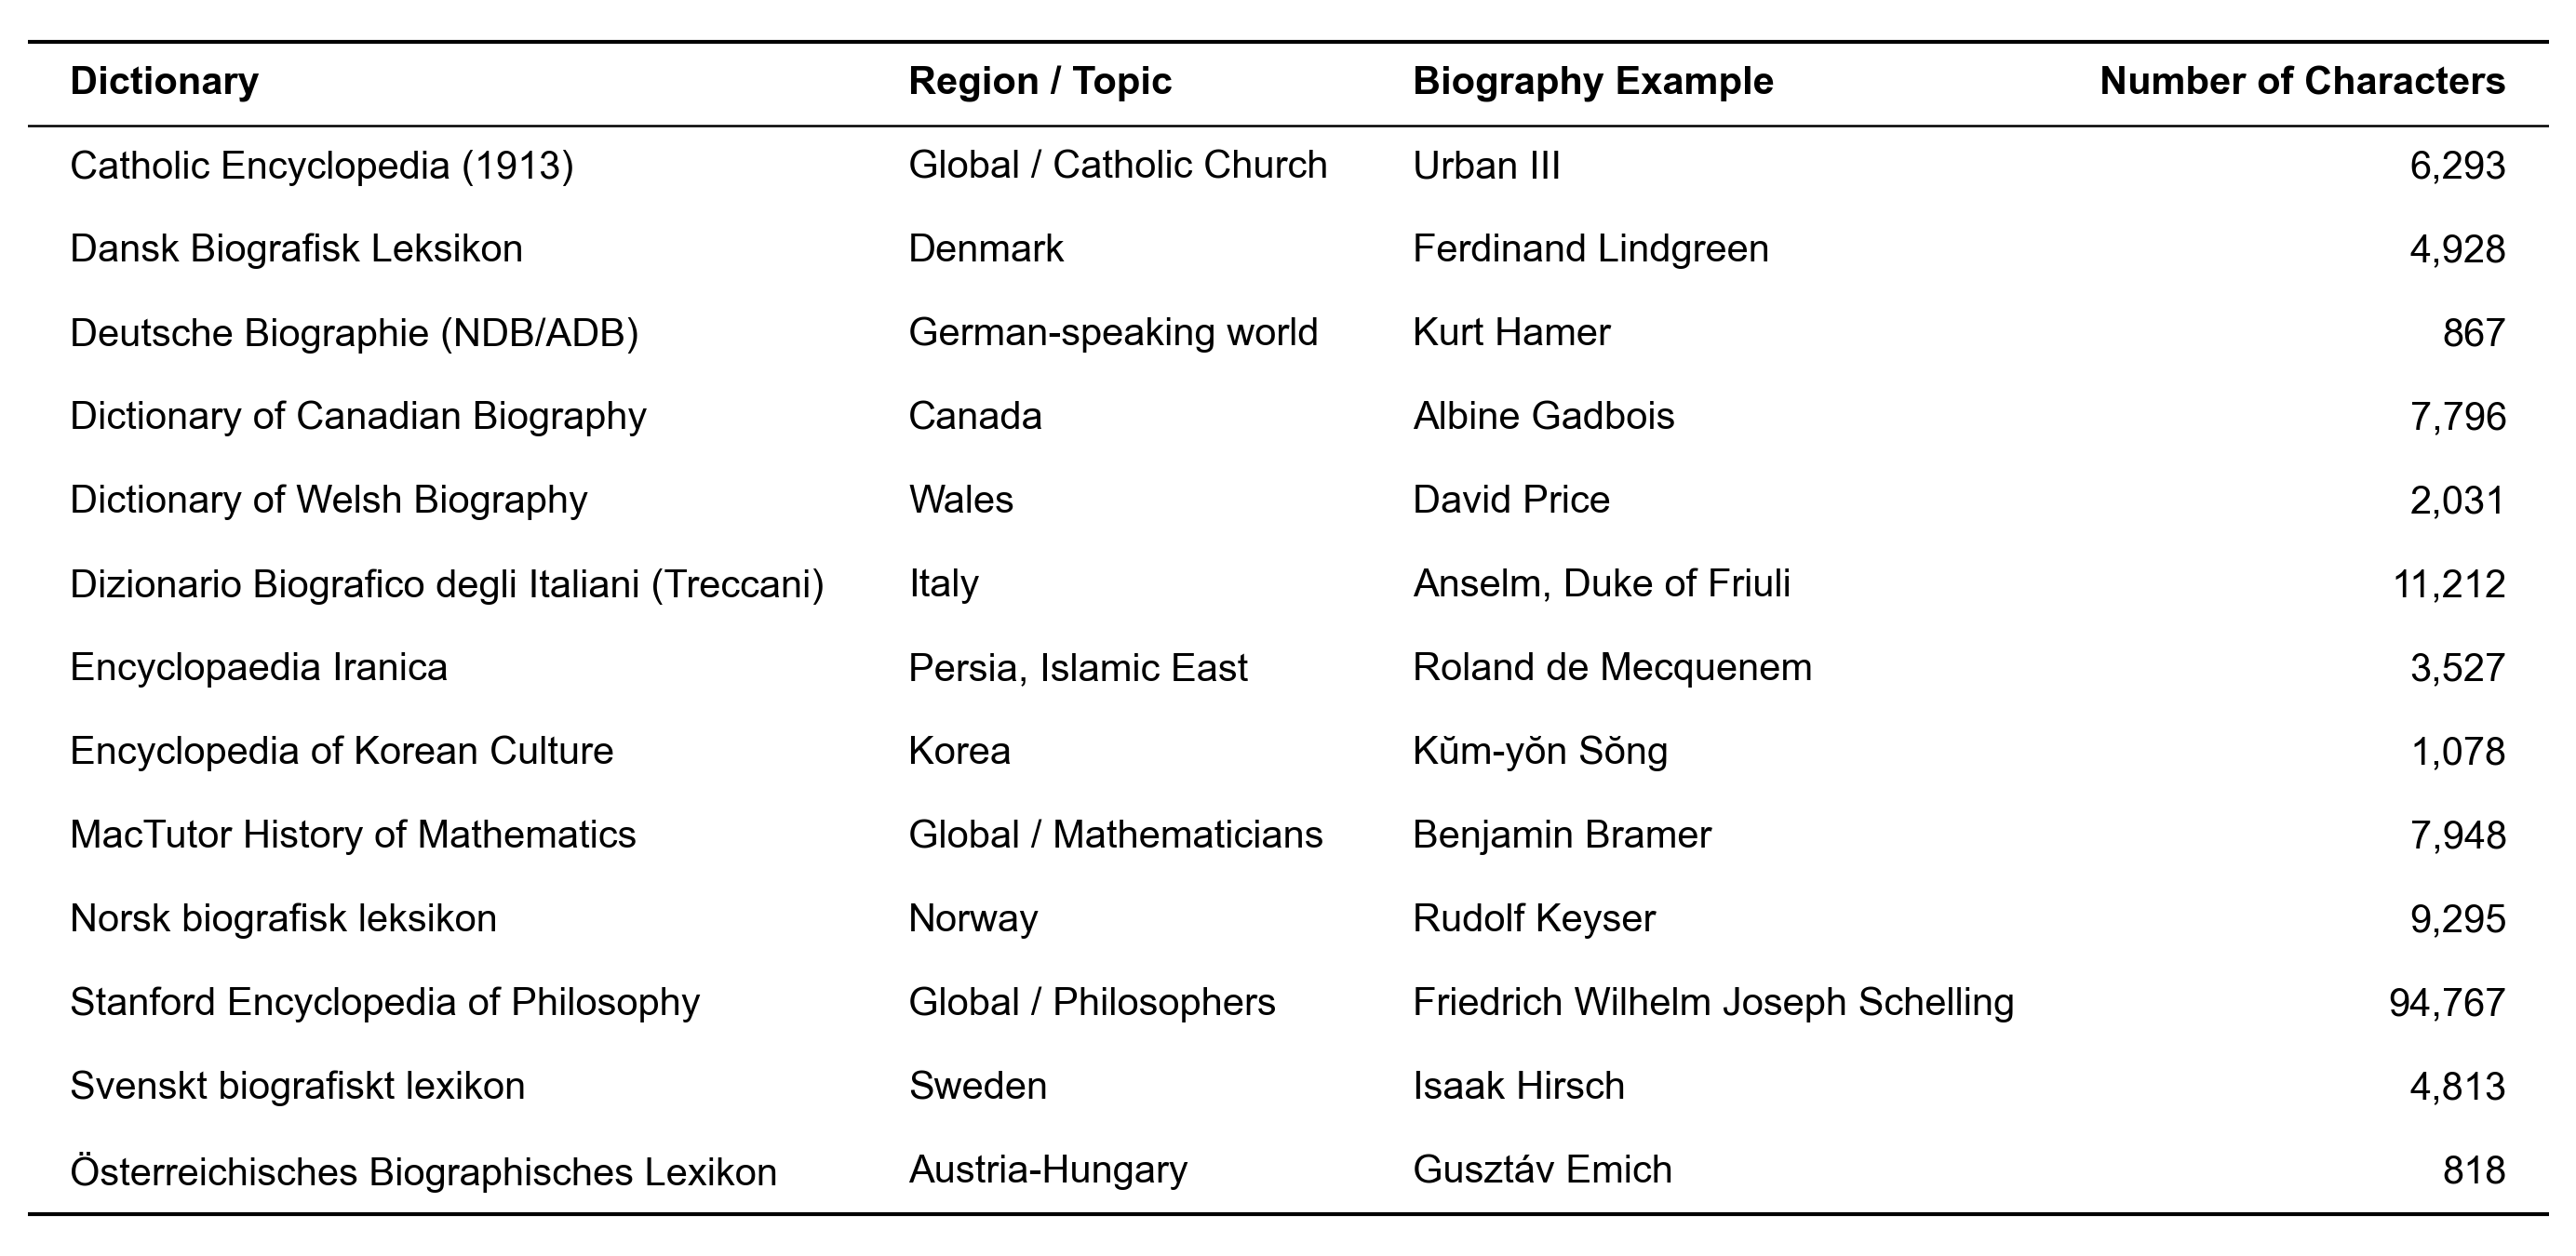

In [3]:
show_table(overview, font_size=10)